# Imports

In [ ]:
# System imports.
import os
import shutil
from pathlib import Path
import subprocess

# Orca imports.
from opi.core import Calculator
from opi.input.simple_keywords import BasisSet, ShellType
from opi.input.structures import Structure
from opi.input.blocks import BlockCasscf, BlockOutput

# CudaQ imports.
from cudaq_algorithms import chemistry
import cudaq

# Quiche imports
import quiche
from quiche.chemistry import HartreeFockState, get_jw_state
from quiche.io import fcidump
from quiche.core import ElectronicHamiltonian, Errors, PhaseEstimation, Simulation
from quiche.cudaq import measured_circuit_kernel, sample_post_processor, textbook_qpe_circuit
from quiche.dispatch import QPESpec

# In-house helper imports
from statePrep.cudaq_circuit_loading import load_circuit_from_json, write_and_import_kernel

In [3]:
# Set ORCA path.
orca_dir = os.path.expanduser("~/Software/orca_6_1_1_macosx_arm64_openmpi411")
os.environ["PATH"] = orca_dir + os.pathsep + os.environ["PATH"]

# Set Julia path.
os.environ["PATH"] = os.path.expanduser("~/.juliaup/bin") + os.pathsep + os.environ["PATH"]

In [4]:
# Check ORCA import path.
print(shutil.which("orca"))

# Check julia import path.
print(shutil.which("julia"))

/Users/xeno.devriendt/Software/orca_6_1_1_macosx_arm64_openmpi411/orca
/Users/xeno.devriendt/.juliaup/bin/julia


# QPE energy vs error

## Step 1: Run ORCA

In [5]:
# Choose the system you will be working with.
system = "H2" # "Fe2S2"

In [6]:
# Work in system specific working directory.
workdir = Path.cwd() / system
workdir.mkdir(exist_ok=True)

# Set up the ORCA calculator.
calc = Calculator(basename=system, working_dir=workdir)
calc.structure = Structure.from_xyz(workdir / (f"{system}.xyz"))
calc.structure.charge, calc.structure.multiplicity = 0, 1
calc.input.ncores = 1
calc.input.add_simple_keywords(ShellType.RHF, BasisSet.STO_3G)

# Set up saving the integrals.
calc.input.add_blocks(BlockCasscf(nel=2, norb=2))

output_block = BlockOutput()
output_block.add_option("DumpActInts", "True")
calc.input.add_blocks(output_block)

# Run the calculation
calc.write_input()
calc.run()

# Extract the output.
output = calc.get_output()
if not output.terminated_normally():
    raise RuntimeError("ORCA did not terminate normally.")
output.parse()

## Step 2: Load into QUICHE via CUDA-Q Algorithms

In [7]:
# Use quiche to parse the fcidump file.
sq_hamiltonian = fcidump.read(str(workdir / f"{system}.fcidump"))
one_body, eri, core = sq_hamiltonian.one_body, sq_hamiltonian.two_body, sq_hamiltonian.core_energy

In [8]:
# Load into cudaQ algorithms
h_cq = chemistry.qubit_hamiltonian(one_body, eri, scalar_offset=core)

## Step 3: DMRG state prep via MPSCircuits.jl

In [9]:
fcidump_path = workdir / f"{system}.fcidump"
circuit_path = workdir / f"{system}_dmrg_circuit.json"   # or keep "h2_dmrg_circuit.json"

out = subprocess.run(
    ["julia", "+1.12", "--project=dmrg_env", "dmrg_circuit.jl", str(fcidump_path), str(circuit_path)],
    capture_output=True, text=True, check=True,
).stdout
print(out)
dmrg_info = dict(line.split("=") for line in out.splitlines() if "=" in line)

dmrg = write_and_import_kernel(load_circuit_from_json(circuit_path))

num_orbitals=2
num_electrons=2
ms2=0
num_qubits=4
dmrg_energy=-1.1372744054909703
max_bond_dim=2
circuit_fidelity=1.0
refined_circuit_fidelity=1.0
circuit_file=/Users/xeno.devriendt/Documents/Git/Forks/quiche/demo/H2/H2_dmrg_circuit.json



Check the overlap between the DMRG state and the true ground state. We see for a simple system like the hydrogen molecule that the DMRG state is exactly the ground state.

In [10]:
num_qubits = int(dmrg_info["num_qubits"])
num_electrons = int(dmrg_info["num_electrons"])


@cudaq.kernel
def dmrg_state():
    q = cudaq.qvector(num_qubits)
    dmrg(q)


# CASSCF over the whole active space, i.e. FCI within the active orbitals.
fci_energy = output.get_final_energy()

hf = HartreeFockState.closed_shell(
    num_electrons=num_electrons, num_spin_orbitals=num_qubits
)
# Jordan-Wigner, as used by chemistry.qubit_hamiltonian; character i is qubit i,
# matching cudaq's State.amplitude convention.
hf_bits = "".join(str(int(b)) for b in get_jw_state(hf.occupation))

print("DMRG energy via CUDA-Q:", cudaq.observe(dmrg_state, h_cq).expectation(), "  FCI:", fci_energy)
print("HF overlap |<HF|DMRG>|^2:", abs(cudaq.get_state(dmrg_state).amplitude(hf_bits)) ** 2)

DMRG energy via CUDA-Q: -1.1372744054909723   FCI: -1.1372744054909694
HF overlap |<HF|DMRG>|^2: 0.9872882676653094


## Step 4: Set up complete QPE circuit

In [11]:
h = quiche.PauliSum.from_cudaq(h_cq)

def get_qpe(error):
    # Split the budget between the Trotter error and the QPE error; QPESpec picks the
    # QPE ancillas and the Trotter time/order/steps from it.
    qpe = QPESpec(
        hamiltonian=ElectronicHamiltonian(
            num_electrons=num_electrons, mapping=quiche.Mapping.JordanWigner, paulis=h
        ),
        state_prep=None,  # the DMRG kernel is injected below instead
        algorithm=PhaseEstimation.Textbook,
        simulation=Simulation.Trotter,
        error_budget=Errors(
            estimation=error / 2,
            simulation=error / 2,
            rotations=error / 2,
            state_prep=error / 2,
            overlap=1.0,
        ),
    )
    kernel, work_qubits, decode = textbook_qpe_circuit(
        h, Simulation.Trotter, qpe.num_qpe_ancillas, qpe.time, qpe.reps, qpe.order,
        n_qubits=qpe.num_data,
    )
    circuit = measured_circuit_kernel(
        kernel, work_qubits, qpe.num_qpe_ancillas, state_prep=dmrg, num_data=qpe.num_data
    )
    post = sample_post_processor(decode, 1)
    return qpe, circuit, post

## Step 5: Run QPE for each error

In [14]:
errors = [2.0, 1.0, 0.5, 0.25, 0.125, 0.0625]# , 0.03125, 0.015625]
shots = 1000

print("Running QPE")

steps, energies = [], []
for error in errors:
    qpe, circuit, post = get_qpe(error)
    # Controlled Trotter-circuit applications per run (2^n - 1) times steps per circuit.
    steps.append((2**qpe.num_qpe_ancillas - 1) * qpe.reps)
    energies.append(post(cudaq.sample(circuit, shots_count=shots)))
    print(f"Completed for error budget {error}")

Running QPE
Completed for error budget 2.0
Completed for error budget 1.0
Completed for error budget 0.5
Completed for error budget 0.25
Completed for error budget 0.125
Completed for error budget 0.0625


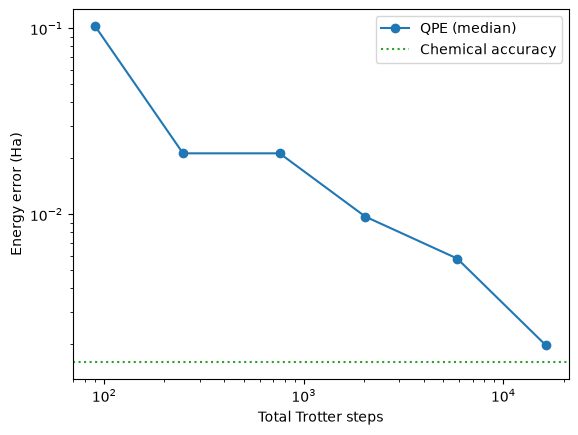

In [15]:
import matplotlib.pyplot as plt
import numpy as np

plt.plot(steps, [abs(np.median(e) - fci_energy) for e in energies], "o-", label="QPE (median)")
plt.axhline(1.6e-3, color="tab:green", ls=":", label="Chemical accuracy")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Total Trotter steps")
plt.ylabel("Energy error (Ha)")
plt.legend()

## Step 6: CUDA-Q Logical

In [16]:
import cudaq.logical as cql
from cudaq_utils import compile_to_p0

qpe, circuit, post = get_qpe(0.5)
source_p0 = compile_to_p0(circuit)

ModuleNotFoundError: No module named 'cudaq.logical'

In [ ]:
from cudaq_utils import profile_table

profile_table(cql.estimate(source_p0, tier=cql.estimate.Tier.LOGICAL))

In [ ]:
from cudaq_utils import synthesize

p0 = synthesize(source_p0, gate_set=cql.compiler.gate_sets.clifford_t, precision=1e-4)
profile_table(cql.estimate(p0, tier=cql.estimate.Tier.LOGICAL))